# 05 - bge-m3 fine-tuning on Kaggle

**Goal:** show the proof of the fine-tuning run: its parameters, the GPU, the training loss and
the retrieval scores before / after, read from MLflow (experiment `tujya-rag-finetuning`), then
its score on the project benchmark. Nothing is downloaded from Kaggle.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import json
import tempfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

In [2]:
import mlflow

from src.utils import mlflow_utils as mu

mu.configure()  # tracking server of docker compose (http://127.0.0.1:5000), read only here
client = mlflow.MlflowClient()
TMP = Path(tempfile.mkdtemp(prefix="tujya-nb-"))  # downloaded artefacts stay outside the repo


def artefact(run_id, path):
    """Download one artefact of a run into a temporary folder and return its local path."""
    return Path(
        mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path=path, dst_path=str(TMP))
    )


def champion(model):
    mv = client.get_model_version_by_alias(model, "champion")
    return mv.run_id, mv.version

In [3]:
experiment = client.get_experiment_by_name("tujya-rag-finetuning")
run = client.search_runs([experiment.experiment_id], "tags.mlflow.runName = 'finetune-bge-m3'")[0]
tags = run.data.tags
print(
    f"run {run.info.run_id[:8]}: base model {tags['base_model']}, "
    f"GPU {tags['gpu']} on {tags['platform']}, "
    f"branch {tags['kaggle_git_branch']}, dataset {tags['dataset']}"
)
pd.Series(run.data.params, name="value").to_frame()

run 03c72c9c: base model BAAI/bge-m3, GPU Tesla T4 on kaggle, branch experiment/fine-tuning-embedding, dataset tujya-rag-finetune-pairs


,value
seed,0
model,BAAI/bge-m3
max_seq_length,384
batch_size,64
mini_batch_size,8
epochs,2
learning_rate,1e-05
warmup_ratio,0.1
weight_decay,0.01
fp16,True


## 1. Training

training: 151.7 min, final loss 0.0917


*Training loss*

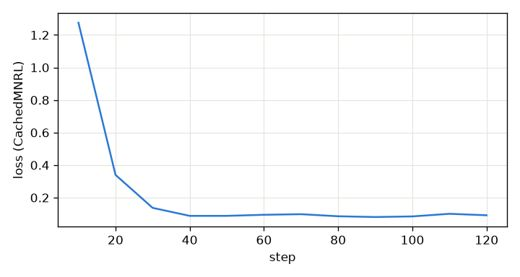

In [4]:
m = run.data.metrics
print(f"training: {m['train_minutes']:.1f} min, final loss {m['train_loss']:.4f}")
show_image(artefact(run.info.run_id, "loss.png"), "Training loss", width=520)

## 2. Before / after on the validation pairs

Retrieval of the right chunk for each held-out question of the fine-tuning set.

In [5]:
fmt(
    pd.DataFrame(
        {
            stage: {
                k: m[f"{stage}_{k}"]
                for k in ("recall_at_1", "recall_at_5", "recall_at_10", "mrr_at_10", "ndcg_at_10")
            }
            for stage in ("base", "tuned")
        }
    ),
    3,
)

,base,tuned
recall_at_1,0.655,0.930
recall_at_5,0.930,0.999
recall_at_10,0.967,1.000
mrr_at_10,0.784,0.960
ndcg_at_10,0.830,0.970


## 3. On the project benchmark (85 questions)

Same sentence-transformers path for the base and the fine-tuned model
(`src/evaluation/results/grid/bge-m3-finetuned.json`).

In [6]:
ft = json.loads(
    (ROOT / "src" / "evaluation" / "results" / "grid" / "bge-m3-finetuned.json").read_text(
        encoding="utf-8"
    )
)
fmt(
    pd.DataFrame(
        [
            {
                "config": k,
                "recall_at_1": v["recall_at_1"],
                "recall_at_5": v["recall_at_5"],
                "recall_at_10": v["recall_at_10"],
                "mrr": v["mrr"],
                "run_id": v["run_id"][:8],
            }
            for k, v in ft.items()
            if isinstance(v, dict) and "mrr" in v
        ]
    ),
    3,
)

,config,recall_at_1,recall_at_5,recall_at_10,mrr,run_id
0,bge-m3-finetuned-dense,0.906,0.929,0.941,0.916,1b6da11e
1,bge-m3-finetuned-hybrid-rewrite,0.859,0.965,0.988,0.898,d96fc302
2,bge-m3-st-dense,0.776,0.906,0.953,0.833,e5300cff
3,bge-m3-st-hybrid-rewrite,0.753,0.906,0.988,0.827,9c2504bf


**Not served:** the API image has no PyTorch to run the fine-tuned model, and its training pairs
come from the same corpus as the benchmark. See `docs/decisions.md`.